# Stroke Prediction
**Data Analysis & Classification**

> **Practical Exploratory Data Analysis and Supervised Machine Learning project** developed in Python to investigate clinical and demographic risk factors associated with Stroke occurrence, comparing the performance and hyperparameter sensitivity of different classifiers.

## Project Overview

The goal of this notebook is to build a complete binary classification pipeline from the **`healthcare-dataset-stroke-data.csv`** dataset ($5,110$ patient records), covering data cleaning and feature transformation through model training, hyperparameter tuning, and comparative evaluation across three distinct families of predictive models.

### Key Workflow Stages

1. **Data Cleaning & Preprocessing (`Pandas` & `Scikit-Learn`):**
   * Data type inspection, missing value identification (`bmi` containing $201$ null records), and removal of discarded columns for modeling (`id`, `bmi`, and `avg_glucose_level`).
   * Standardization of the numerical feature `age` and cardinality analysis of categorical attributes (`gender`, `ever_married`, `work_type`, `Residence_type`, and `smoking_status`).
   * Encoding of qualitative variables using `LabelEncoder` followed by `OneHotEncoder` (`ColumnTransformer`), expanding the feature matrix to $19$ features.
   * Standard normal ($z$-score) scaling with `StandardScaler` and stratified splitting into training ($85\%$) and testing ($15\%$) sets.

2. **Exploratory Analysis & Correlation (`Seaborn` & `Matplotlib`):**
   * Generation of a correlation heatmap using **Spearman's rank correlation coefficient** to evaluate monotonic relationships between age, hypertension, heart disease history, and the target variable (`stroke`).

3. **Comparative Modeling & Hyperparameter Tuning:**
   * **Logistic Regression (`LogisticRegression`):** Baseline evaluation using a confusion matrix (`Yellowbrick`) and experimentation across $6$ combinations of penalties (`l1`, `l2`, `elasticnet`, `none`) and solvers (`newton-cg`, `saga`, `sag`, `liblinear`), achieving **$94.65\%$** accuracy.
   * **Artificial Neural Network (`MLPClassifier`):** Comparative experiments across optimizers (`sgd` with constant or `invscaling` learning rates, with and without Nesterov momentum, and `adam`), tracked via training loss curves over epochs, reaching up to **$94.65\%$** accuracy.
   * **Linear Discriminant Analysis (`LinearDiscriminantAnalysis`):** Comparison between `svd` and `lsqr` solvers across multiple regularization factors (`shrinkage`: `auto`, `0.1`, `0.75`), achieving a peak accuracy of **$93.61\%$**.

## Technologies Used

* **Language:** Python 3
* **Data Manipulation & Analysis:** Pandas, NumPy
* **Machine Learning & Preprocessing:** Scikit-Learn (`ColumnTransformer`, `OneHotEncoder`, `StandardScaler`, `LogisticRegression`, `MLPClassifier`, `LinearDiscriminantAnalysis`)
* **Visualization & Diagnostics:** Matplotlib, Seaborn, Yellowbrick (`ConfusionMatrix`)

#### **`Imports`**

In [ ]:
import math
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler 
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from yellowbrick.classifier import ConfusionMatrix
import matplotlib.pyplot as plt
import warnings


##### **`Pré-Processamento`**

In [ ]:
data = pd.read_csv("healthcare-dataset-stroke-data.csv")

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [ ]:
missing_values = data.isnull().sum()
print(missing_values)

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [ ]:
#remocao da coluna id, bmi e avg_glucose_level
data.drop('id', axis=1, inplace=True)
data.drop('bmi', axis=1, inplace=True)
data.drop('avg_glucose_level', axis=1, inplace=True)

In [ ]:
#conversao da coluna 'age', do tipo 'float' para 'int'
data['age'] = data['age'].astype('int')

In [ ]:
#exibicao dos valores distintos dos atributos qualitativos
for col in data.columns:
    if (data[col].dtype == 'object'):
        print(col,data[col].unique())

gender ['Male' 'Female' 'Other']
ever_married ['Yes' 'No']
work_type ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
Residence_type ['Urban' 'Rural']
smoking_status ['formerly smoked' 'never smoked' 'smokes' 'Unknown']


In [ ]:
data.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,smoking_status,stroke
0,Male,67,0,1,Yes,Private,Urban,formerly smoked,1
1,Female,61,0,0,Yes,Self-employed,Rural,never smoked,1
2,Male,80,0,1,Yes,Private,Rural,never smoked,1
3,Female,49,0,0,Yes,Private,Urban,smokes,1
4,Female,79,1,0,Yes,Self-employed,Rural,never smoked,1


In [ ]:
#divisao entre previsores e classe
X_strokes = data.iloc[:, 0:8].values
y_strokes = data.iloc[:, 8].values

In [ ]:
#utilizacao do LabelEncoder para transformacao dos atributos categoricos
label_encoder_gender = LabelEncoder()
label_encoder_ever_married = LabelEncoder()
label_encoder_work_type = LabelEncoder()
label_encoder_residence_type = LabelEncoder()
label_encoder_smoking_status = LabelEncoder()

X_strokes[:, 0] = label_encoder_gender.fit_transform(X_strokes[:, 0])
X_strokes[:, 4] = label_encoder_ever_married.fit_transform(X_strokes[:, 4])
X_strokes[:, 5] = label_encoder_work_type.fit_transform(X_strokes[:, 5])
X_strokes[:, 6] = label_encoder_residence_type.fit_transform(X_strokes[:, 6])
X_strokes[:, 7] = label_encoder_smoking_status.fit_transform(X_strokes[:, 7])

In [ ]:
#implementacao do OneHotEncoder
onehotencoder_strokes = ColumnTransformer(transformers=[('OneHot', OneHotEncoder(), [0,4,5,6,7])], remainder='passthrough')

X_strokes = onehotencoder_strokes.fit_transform(X_strokes)

X_strokes.shape

(5110, 19)

In [ ]:
#escalonamento dos atributos
scaler_strokes = StandardScaler()
X_strokes = scaler_strokes.fit_transform(X_strokes)

In [ ]:
#divisao entre bases de treinamento e teste
X_strokes_treinamento, X_strokes_teste, y_strokes_treinamento, y_strokes_teste = train_test_split(X_strokes, y_strokes, test_size=0.15, random_state=0)
print(X_strokes_teste)

[[-1.18950991  1.18998977 -0.01399046 ...  1.71373869 -0.32860186
   4.18503199]
 [-1.18950991  1.18998977 -0.01399046 ... -1.73276197 -0.32860186
  -0.2389468 ]
 [-1.18950991  1.18998977 -0.01399046 ...  0.65327694 -0.32860186
  -0.2389468 ]
 ...
 [ 0.84068236 -0.84034336 -0.01399046 ...  0.83002057 -0.32860186
  -0.2389468 ]
 [-1.18950991  1.18998977 -0.01399046 ... -1.68857607 -0.32860186
  -0.2389468 ]
 [ 0.84068236 -0.84034336 -0.01399046 ... -0.31881298 -0.32860186
  -0.2389468 ]]


In [ ]:
lista_compara_scores = []
lista_compara_accuracy = []

<AxesSubplot:>

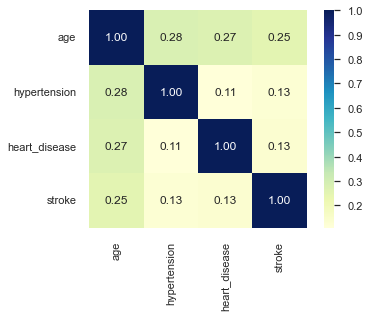

In [ ]:
sns.set_theme(style="darkgrid")
sns.heatmap(data.corr(method='spearman'), annot=True, cmap='YlGnBu', fmt='.2f', square=True)


##### **`Análises:`**


##### **`Regressão Logística`**

In [ ]:
logistic_strokes = LogisticRegression(random_state=1, max_iter=120)

logistic_strokes.fit(X_strokes_treinamento, y_strokes_treinamento)

LogisticRegression(max_iter=120, random_state=1)

In [ ]:
logistic_strokes.intercept_

array([-4.08333984])

In [ ]:
#realizacao dos calculos de regressao logistica
previsoes = logistic_strokes.predict(X_strokes_teste)

In [ ]:
#calculo da taxa de acerto
accuracy = accuracy_score(y_strokes_teste, previsoes)
lista_compara_accuracy.append(accuracy)
accuracy

0.9465449804432855

0.9465449804432855

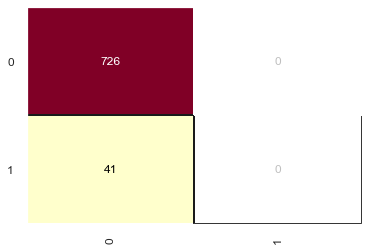

In [ ]:
#criacao e exibicao da matriz de confusao
cm = ConfusionMatrix(logistic_strokes)
cm.fit(X_strokes_treinamento, y_strokes_treinamento)
cm.score(X_strokes_teste, y_strokes_teste)

In [ ]:
params = [
    {
        "penalty": "l2",
        "fit_intercept": True,
        "solver": "newton-cg",
    },
    {
        "penalty": "none",
        "fit_intercept": False,
        "solver": "newton-cg",
    },
    {
        "penalty": "elasticnet",
        "l1_ratio": 1,
        "fit_intercept": False,
        "solver": "saga",
    },
    {
        "penalty": "l1",
        "fit_intercept": True,
        "solver": "saga",
    },
    {
        "penalty": "none",
        "fit_intercept": False,
        "solver": "sag",
    },
    {
        "penalty": "l1",
        "fit_intercept": True,
        "solver": "liblinear",
    }
]

scores_list = []

labels = [
    "teste-hiperparametros-1",
    "teste-hiperparametros-2",
    "teste-hiperparametros-3",
    "teste-hiperparametros-4",
    "teste-hiperparametros-5",
    "teste-hiperparametros-6",
]

accuracy_list = []

for label, param in zip(labels, params):
        print("Training: %s" % label)
        lr = LogisticRegression(random_state=1, max_iter=120, **param)
        
        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore", category=ConvergenceWarning, module="sklearn"
            )
            lr.fit(X_strokes_treinamento, y_strokes_treinamento)
            
        y_predict = lr.predict(X_strokes_teste)
        accuracy = accuracy_score(y_strokes_teste, y_predict)
        accuracy_list.append(accuracy)

        score = lr.score(X_strokes_treinamento, y_strokes_treinamento)
        scores_list.append(score)
            
        print("Treinamento accuracy: %f" % accuracy)

df_scores_accuracy = pd.DataFrame({'Labels' : labels, 'Accuracy': accuracy_list})
print(df_scores_accuracy)

accuracy_list.sort(reverse=True)

print("Maior Accuracy: %f" % accuracy_list[0]) 

Training: teste-hiperparametros-1
Treinamento accuracy: 0.946545
Training: teste-hiperparametros-2
Treinamento accuracy: 0.604954
Training: teste-hiperparametros-3
Treinamento accuracy: 0.604954
Training: teste-hiperparametros-4
Treinamento accuracy: 0.946545
Training: teste-hiperparametros-5
Treinamento accuracy: 0.604954
Training: teste-hiperparametros-6
Treinamento accuracy: 0.946545
                    Labels  Accuracy
0  teste-hiperparametros-1  0.946545
1  teste-hiperparametros-2  0.604954
2  teste-hiperparametros-3  0.604954
3  teste-hiperparametros-4  0.946545
4  teste-hiperparametros-5  0.604954
5  teste-hiperparametros-6  0.946545
Maior Accuracy: 0.946545


##### **`Rede neural - MLPClassifier`**

In [ ]:
# Parametros baseados nos testes com diferentes hiperparametros
mlp = MLPClassifier(solver='adam', random_state=0,max_iter=1000, learning_rate_init=0.01)

mlp.fit(X_strokes_treinamento, y_strokes_treinamento)

MLPClassifier(learning_rate_init=0.01, max_iter=1000, random_state=0)

In [ ]:
y_predict = mlp.predict(X_strokes_teste)

In [ ]:
accuracy = accuracy_score(y_strokes_teste, y_predict)
lista_compara_accuracy.append(accuracy)
accuracy

0.9452411994784876

training: constante learning-rate
Treinamento perda: 0.136415
Treinamento accuracy: 0.946545
Curva de Perda plot: 


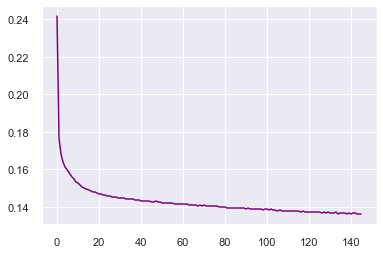

training: constante com momentum
Treinamento perda: 0.137299
Treinamento accuracy: 0.946545
Curva de Perda plot: 


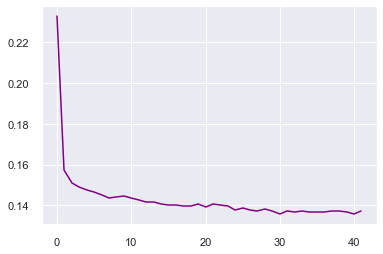

training: constante com Nesterov's momentum
Treinamento perda: 0.125971
Treinamento accuracy: 0.940026
Curva de Perda plot: 


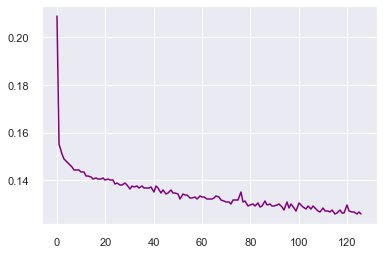

training: inv-scaling learning-rate
Treinamento perda: 0.181000
Treinamento accuracy: 0.946545
Curva de Perda plot: 


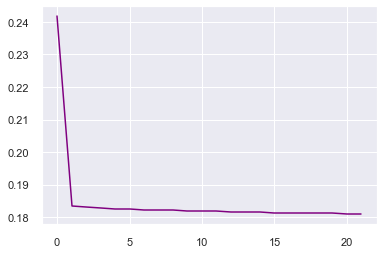

training: inv-scaling com momentum
Treinamento perda: 0.152795
Treinamento accuracy: 0.946545
Curva de Perda plot: 


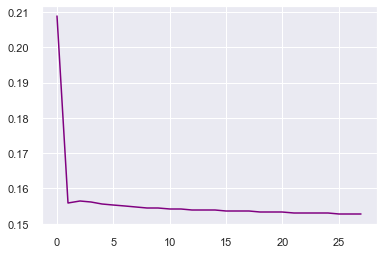

training: inv-scaling com Nesterov's momentum
Treinamento perda: 0.154354
Treinamento accuracy: 0.946545
Curva de Perda plot: 


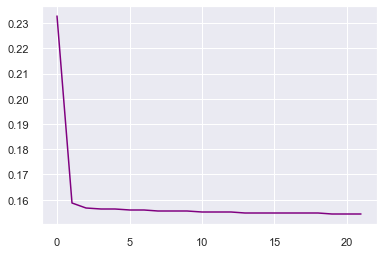

training: adam
Treinamento perda: 0.121848
Treinamento accuracy: 0.945241
Curva de Perda plot: 


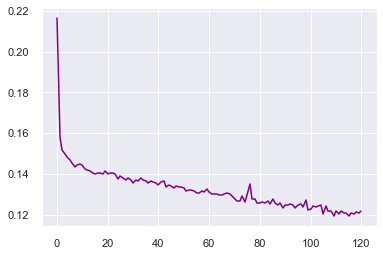

                                Labels  Accuracy
0              constante learning-rate  0.946545
1               constante com momentum  0.946545
2    constante com Nesterov's momentum  0.940026
3            inv-scaling learning-rate  0.946545
4             inv-scaling com momentum  0.946545
5  inv-scaling com Nesterov's momentum  0.946545
6                                 adam  0.945241
Maior Accuracy: 0.946545


In [ ]:
params = [
    {
        "solver": "sgd",
        "learning_rate": "constant",
        "momentum": 0,
        "learning_rate_init": 0.2,
    },
    {
        "solver": "sgd",
        "learning_rate": "constant",
        "momentum": 0.9,
        "nesterovs_momentum": False,
        "learning_rate_init": 0.2,
    },
    {
        "solver": "sgd",
        "learning_rate": "constant",
        "momentum": 0.9,
        "nesterovs_momentum": True,
        "learning_rate_init": 0.2,
    },
    {
        "solver": "sgd",
        "learning_rate": "invscaling",
        "momentum": 0,
        "learning_rate_init": 0.2,
    },
    {
        "solver": "sgd",
        "learning_rate": "invscaling",
        "momentum": 0.9,
        "nesterovs_momentum": True,
        "learning_rate_init": 0.2,
    },
    {
        "solver": "sgd",
        "learning_rate": "invscaling",
        "momentum": 0.9,
        "nesterovs_momentum": False,
        "learning_rate_init": 0.2,
    },
    {"solver": "adam", "learning_rate_init": 0.01},
]

labels = [
    "constante learning-rate",
    "constante com momentum",
    "constante com Nesterov's momentum",
    "inv-scaling learning-rate",
    "inv-scaling com momentum",
    "inv-scaling com Nesterov's momentum",
    "adam",
]

accuracy_list = []


for label, param in zip(labels, params):
        print("training: %s" % label)
        mlp = MLPClassifier(random_state=0, max_iter=1000, **param)

        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore", category=ConvergenceWarning, module="sklearn"
            )
            mlp.fit(X_strokes_treinamento, y_strokes_treinamento)
            
        
        y_predict = mlp.predict(X_strokes_teste)
        accuracy = accuracy_score(y_strokes_teste, y_predict)
        accuracy_list.append(accuracy)
        
        
        print("Treinamento perda: %f" % mlp.loss_)
        print("Treinamento accuracy: %f" % accuracy)
        print("Curva de Perda plot: ")
        plt.plot(mlp.loss_curve_, c="purple", linestyle="-", fillstyle="bottom", rasterized=True,snap=True, animated=True)
        plt.show()


df_scores_accuracy = pd.DataFrame({'Labels' : labels, 'Accuracy': accuracy_list})
print(df_scores_accuracy)

accuracy_list.sort(reverse=True)

print("Maior Accuracy: %f" % accuracy_list[0])

##### **`Análise Discriminante - LDA`**

In [ ]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_strokes_treinamento,y_strokes_treinamento)

LinearDiscriminantAnalysis()

In [ ]:
y_pred = lda.predict(X_strokes_teste)

In [ ]:
accuracy = accuracy_score(y_strokes_teste, y_pred)
lista_compara_accuracy.append(accuracy)


In [ ]:
params = [
    {
        "solver": "svd",
    },
    {
        "solver": "lsqr",
        "shrinkage":"auto",
    },
    {
        "solver": "lsqr",
        "shrinkage":0.1,
    },
    {
        "solver": "lsqr",
        "shrinkage":0.75,
    },
]

labels = [
    "método svd com shrinkage em none",
    "método lsqr com shrinkage em auto",
    "método lsqr com shrinkage em 0.1",
    "método lsqr com shrinkage em 0.75",
]

accuracy_list = []


for label, param in  zip(labels, params):

        print("training: %s" % label)

        lda = LinearDiscriminantAnalysis(**param)
        
        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore", category=ConvergenceWarning, module="sklearn"
            )
            lda.fit(X_strokes_treinamento, y_strokes_treinamento)

        y_pred = lda.predict(X_strokes_teste)
        accuracy = accuracy_score(y_strokes_teste, y_pred)
        accuracy_list.append(accuracy)
        print("Acuracia: %f" % accuracy)
        
df_scores_accuracy = pd.DataFrame({'Labels' : labels, 'Accuracy': accuracy_list})
print(df_scores_accuracy)

accuracy_list.sort(reverse=True)

print("Maior Accuracy: %f" % accuracy_list[0])



training: método svd com shrinkage em none
Acuracia: 0.936115
training: método lsqr com shrinkage em auto
Acuracia: 0.934811
training: método lsqr com shrinkage em 0.1
Acuracia: 0.934811
training: método lsqr com shrinkage em 0.75
Acuracia: 0.913950
                              Labels  Accuracy
0   método svd com shrinkage em none  0.936115
1  método lsqr com shrinkage em auto  0.934811
2   método lsqr com shrinkage em 0.1  0.934811
3  método lsqr com shrinkage em 0.75  0.913950
Maior Accuracy: 0.936115
